# Lab — Logistic Regression from scratch
**Machine Learning SUP'COM workshop**

**Goal:** understand logistic regression by building a small class ourselves, then compare it with scikit-learn.

How this lab works:

- Fill in every `# TODO` and replace each `raise NotImplementedError`.
- Run the cells **in order**, from top to bottom.
- Each task ends with a **Check yourself** cell: compare your output with the expected values. If they do not match, fix your code before moving on: later tasks reuse earlier ones.
- Cells marked `# ---- PROVIDED` are complete: just run and read them.
- When you see *Your answer:* ..., write a short answer in that markdown cell.

```text
Problem → Dataset → Visualization → Math idea → Build a class → Train
       → Visualize what it learned → scikit-learn → Compare → Experiments
```

In [1]:
# ---- PROVIDED
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (6, 4)
np.set_printoptions(precision=4, suppress=True)

## Part A. The problem

### Task 1. Load and look at the data

> **What are we trying to predict?**

Each example has two features and belongs to one of two classes, $y \in \{0, 1\}$.

In [2]:
# ---- PROVIDED
from sklearn.datasets import make_classification

X, y = make_classification(
    n_samples=100,
    n_features=2,
    n_redundant=0,
    n_informative=2,
    n_clusters_per_class=1,
    class_sep=2.5,
    random_state=42
)

X shape: (100, 2)
y shape: (100,)
First 5 rows of X:
 [[ 2.7283 -2.2572]
 [ 2.1984 -2.8803]
 [ 4.0488  4.0023]
 [ 2.0736 -2.853 ]
 [ 2.0859 -2.8375]]
First 5 labels: [0 0 1 0 0]
Examples per class: [50 50]


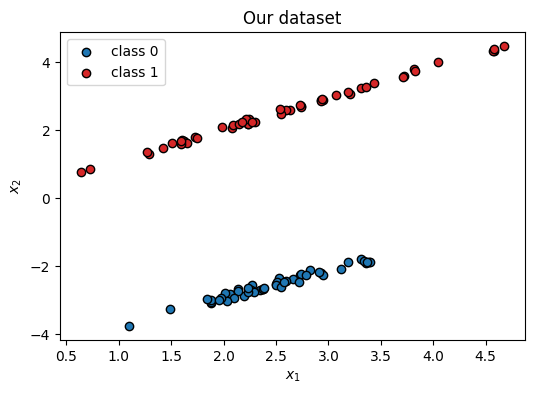

In [3]:
print("X shape:", X.shape)
print("y shape:", y.shape)
print("First 5 rows of X:\n", X[:5])
print("First 5 labels:", y[:5])
print("Examples per class:", np.bincount(y))

plt.scatter(X[y == 0, 0], X[y == 0, 1], c="tab:blue", label="class 0", edgecolor="k")
plt.scatter(X[y == 1, 0], X[y == 1, 1], c="tab:red",  label="class 1", edgecolor="k")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("Our dataset")
plt.legend()
plt.show()

> **Can we separate these two groups with a line?**

*Answer:* yes. The two classes form two separate elongated clouds, and a line can be drawn between them with zero errors.

**Check yourself:** `X` is (100, 2), `y` is (100,). 50 examples per class. First labels `[0 0 1 0 0]`; first row of `X` is `[2.7283 -2.2572]`.

## Part B. From a line to a probability

### Task 2. The linear score

> **What does the model need to learn?**

$$
z = w^T x + b = w_1 x_1 + w_2 x_2 + b
$$

| Symbol | Meaning |
|---|---|
| $x$ | the input (one row of `X`) |
| $w$ | the **weights**, one per feature |
| $b$ | the **bias** |
| $z$ | the **score**: a single number |

The points where $w^T x + b = 0$ form the **decision boundary**.

In [4]:
w = np.array([0.5, -1.0])
b = 0.5
x = np.array([2.0, 1.0])

z = w @ x + b
print("score for one example:", z)

z_all = X[:5] @ w + b
print("scores for the first 5 examples:", z_all)

score for one example: 0.5
scores for the first 5 examples: [ 4.1213  4.4795 -1.4778  4.3898  4.3804]


To draw the line $w^Tx + b = 0$, solve it for $x_2$:

$$
x_2 = -\frac{w_1 x_1 + b}{w_2}
$$

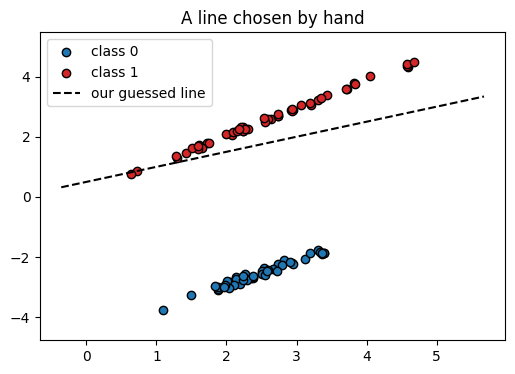

In [5]:
x1_line = np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 100)
x2_line = -(w[0] * x1_line + b) / w[1]

plt.scatter(X[y == 0, 0], X[y == 0, 1], c="tab:blue", label="class 0", edgecolor="k")
plt.scatter(X[y == 1, 0], X[y == 1, 1], c="tab:red",  label="class 1", edgecolor="k")
plt.plot(x1_line, x2_line, "k--", label="our guessed line")
plt.ylim(X[:, 1].min() - 1, X[:, 1].max() + 1)
plt.legend()
plt.title("A line chosen by hand")
plt.show()

**Check yourself:** the score of `x` is `0.5`. The first 5 scores are `[4.1213 4.4795 -1.4778 4.3898 4.3804]`. The hand-picked line does **not** separate the classes: we need the computer to learn $w$ and $b$.

### Task 3. The sigmoid

The score $z$ can be any number. It is **not** a probability. The sigmoid squashes it into $(0, 1)$:

$$
\sigma(z) = \frac{1}{1 + e^{-z}}, \qquad P(y = 1 \mid x) = \sigma(w^T x + b)
$$

0.5 0.9933071490757153 0.0066928509242848554
[0.1192 0.5    0.8808]


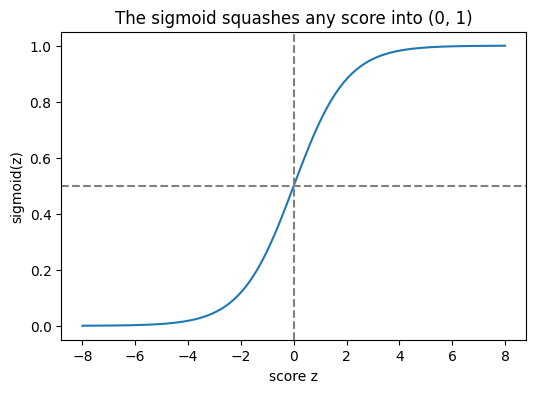

In [6]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))


print(sigmoid(0), sigmoid(5), sigmoid(-5))
print(sigmoid(np.array([-2.0, 0.0, 2.0])))

z_values = np.linspace(-8, 8, 200)
plt.plot(z_values, sigmoid(z_values))
plt.axhline(0.5, color="gray", linestyle="--")
plt.axvline(0, color="gray", linestyle="--")
plt.xlabel("score z")
plt.ylabel("sigmoid(z)")
plt.title("The sigmoid squashes any score into (0, 1)")
plt.show()

**Check yourself:** `0.5 0.9933 0.0067`, then `[0.1192 0.5 0.8808]`.

> What probability does the model give to a point **exactly on** the decision boundary?

*Answer:* on the boundary $z = 0$, so $p = \sigma(0) = 0.5$: the model has no preference.

### Task 4. The loss

> **How do we know if the prediction is good?**

Binary cross-entropy for one example:

$$
L(y, p) = -\left[\, y \log(p) + (1 - y)\log(1 - p) \,\right]
$$

and the cost over $m$ examples:

$$
J(w, b) = \frac{1}{m} \sum_{i=1}^{m} L_i
$$

true y = 1, predicted p = 0.99  -> loss = 0.010
true y = 1, predicted p = 0.9   -> loss = 0.105
true y = 1, predicted p = 0.6   -> loss = 0.511
true y = 1, predicted p = 0.5   -> loss = 0.693
true y = 1, predicted p = 0.1   -> loss = 2.303
true y = 1, predicted p = 0.01  -> loss = 4.605


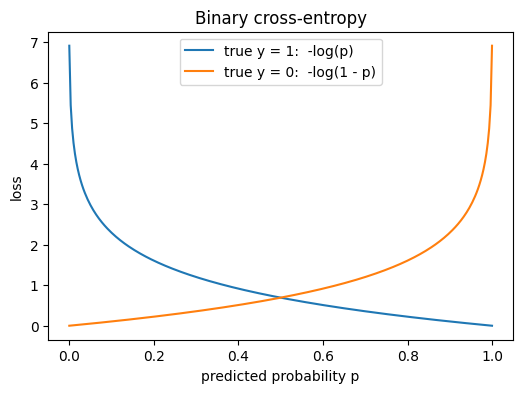

In [7]:
def bce(y_true, p):
    return -(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))


for p in [0.99, 0.9, 0.6, 0.5, 0.1, 0.01]:
    print(f"true y = 1, predicted p = {p:<5} -> loss = {bce(1, p):.3f}")

p_values = np.linspace(0.001, 0.999, 300)
plt.plot(p_values, -np.log(p_values),     label="true y = 1:  -log(p)")
plt.plot(p_values, -np.log(1 - p_values), label="true y = 0:  -log(1 - p)")
plt.xlabel("predicted probability p")
plt.ylabel("loss")
plt.title("Binary cross-entropy")
plt.legend()
plt.show()

**Check yourself:** losses `0.010, 0.105, 0.511, 0.693, 2.303, 4.605`.

> Compare a *confident wrong* prediction ($p = 0.01$ for a true class 1) with a *hesitant wrong* one ($p = 0.4$). Why is this behaviour useful?

*Answer:* the confident mistake costs about 4.6, the hesitant one about 0.92. The loss explodes as the model becomes confidently wrong, so training pushes hardest on the worst mistakes.

## Part C. Build the model

### Task 5. Gradient descent, on paper

> **How can we improve the parameters?**

With $z = Xw + b$ and $p = \sigma(z)$, the gradients of $J$ are:

$$
\nabla_w J = \frac{1}{m} X^T (p - y), \qquad
\frac{\partial J}{\partial b} = \frac{1}{m}\sum_{i=1}^{m} (p_i - y_i)
$$

and the update, with learning rate $\eta$:

$$
w \leftarrow w - \eta \, \nabla_w J, \qquad
b \leftarrow b - \eta \, \frac{\partial J}{\partial b}
$$

> 1. What is the shape of `X.T @ (p - y)` for our data? Why does it match the shape of `w`?
> 2. How can you read the vector $p - y$ in words?

*Answer:* (1) `X.T` is (2, 100) and `p - y` is (100,), so the product is (2,): one gradient value per weight, same shape as `w`. (2) $p - y$ is the **error** of each prediction: positive when the model says too much class 1, negative when it says too little.

### Task 6. The `LogisticRegressionScratch` class

Real ML libraries organise every model the same way:

```python
model = SomeModel(hyperparameters)   # create: nothing learned yet
model.fit(X, y)                      # learn the parameters
model.predict(X_new)                 # use them
```

| Attribute | Set in | Meaning |
|---|---|---|
| `self.lr`, `self.epochs` | `__init__` | hyperparameters: chosen by **us** |
| `self.w`, `self.b` | `fit` | parameters: learned from **data** |
| `self.loss_history` | `fit` | the cost at each epoch |

Before training, the model does not know $w$ and $b$. After `model.fit(X, y)`, the object **contains** them. That is what `self` is for.

Rules: no helper functions outside the class, keep all the maths visible inside `fit`.

In [8]:
class LogisticRegressionScratch:

    def __init__(self, lr=0.1, epochs=1000):
        self.lr = lr
        self.epochs = epochs

    def sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        m, n = X.shape

        self.w = np.zeros(n)
        self.b = 0.0
        self.loss_history = []

        for epoch in range(self.epochs):
            # 1. Forward pass
            z = X @ self.w + self.b
            p = self.sigmoid(z)

            # 2. Cost
            p_safe = np.clip(p, 1e-12, 1 - 1e-12)
            loss = -np.mean(y * np.log(p_safe) + (1 - y) * np.log(1 - p_safe))
            self.loss_history.append(loss)

            # 3. Gradients
            dw = (1 / m) * X.T @ (p - y)
            db = (1 / m) * np.sum(p - y)

            # 4. Update
            self.w = self.w - self.lr * dw
            self.b = self.b - self.lr * db

        return self

    def predict_proba(self, X):
        return self.sigmoid(X @ self.w + self.b)

    def predict(self, X):
        return (self.predict_proba(X) >= 0.5).astype(int)

### Task 7. Train it

In [9]:
model = LogisticRegressionScratch(lr=0.1, epochs=1000)

print("Has w before fit?", hasattr(model, "w"))

model.fit(X, y)

print("Has w after fit? ", hasattr(model, "w"))
print("Learned weights w:", model.w)
print("Learned bias b:   ", model.b)

proba = model.predict_proba(X)
pred = model.predict(X)
accuracy = np.mean(pred == y)
print("First 5 probabilities:", proba[:5])
print("First 5 predictions:  ", pred[:5])
print("Training accuracy:", accuracy)

Has w before fit? False
Has w after fit?  True
Learned weights w: [-0.0293  2.7944]
Learned bias b:    0.3411549584871792
First 5 probabilities: [0.0024 0.0004 1.     0.0005 0.0005]
First 5 predictions:   [0 0 1 0 0]
Training accuracy: 1.0


**Check yourself:** `False` then `True`. `w = [-0.0293 2.7944]`, `b ≈ 0.3412`. First probabilities `[0.0024 0.0004 1. 0.0005 0.0005]`, predictions `[0 0 1 0 0]`, accuracy `1.0`.

### Task 8. Watch the training loss

> The optimization process is trying to make this curve go down.

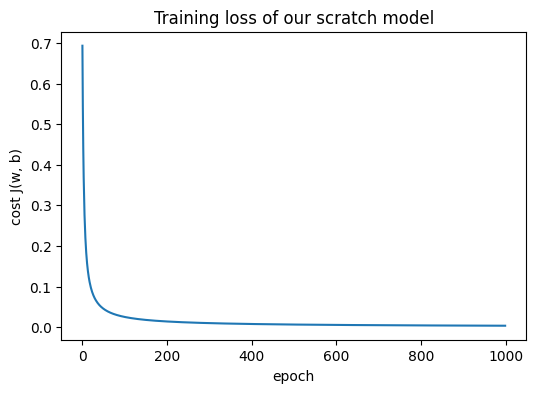

Loss at the start: 0.6931
Loss at the end:   0.0037


In [10]:
plt.plot(model.loss_history)
plt.xlabel("epoch")
plt.ylabel("cost J(w, b)")
plt.title("Training loss of our scratch model")
plt.show()

print("Loss at the start:", round(model.loss_history[0], 4))
print("Loss at the end:  ", round(model.loss_history[-1], 4))

**Check yourself:** start `0.6931`, end `0.0037`.

> Why is the very first loss exactly $\log 2 \approx 0.693$?

*Answer:* at epoch 0, $w = 0$ and $b = 0$, so every score is 0 and every probability is 0.5. Each example then costs $-\log(0.5) = \log 2$: the model knows nothing yet.

## Part D. Visualize what it learned

The function below asks a model to predict on a fine grid and colours each region by its predicted class. It only calls `model.predict`, so it works for **any** model that has that method.

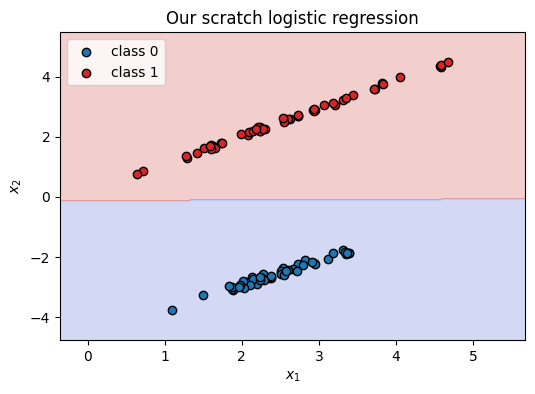

In [11]:
# ---- PROVIDED
def plot_decision_boundary(model, X, y, title, ax=None):
    if ax is None:
        ax = plt.gca()

    x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx1, xx2 = np.meshgrid(np.linspace(x1_min, x1_max, 300),
                           np.linspace(x2_min, x2_max, 300))
    grid = np.c_[xx1.ravel(), xx2.ravel()]

    Z = model.predict(grid).reshape(xx1.shape)

    ax.contourf(xx1, xx2, Z, alpha=0.25, cmap="coolwarm")
    ax.scatter(X[y == 0, 0], X[y == 0, 1], c="tab:blue", label="class 0", edgecolor="k")
    ax.scatter(X[y == 1, 0], X[y == 1, 1], c="tab:red",  label="class 1", edgecolor="k")
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_title(title)
    ax.legend()


plot_decision_boundary(model, X, y, "Our scratch logistic regression")
plt.show()

### Task 9. The probability map

Instead of the predicted class, draw the **probability** of class 1 on the grid.

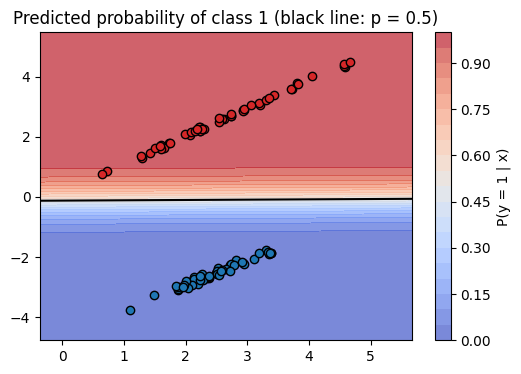

In [12]:
x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx1, xx2 = np.meshgrid(np.linspace(x1_min, x1_max, 300),
                       np.linspace(x2_min, x2_max, 300))

P = model.predict_proba(np.c_[xx1.ravel(), xx2.ravel()]).reshape(xx1.shape)

plt.contourf(xx1, xx2, P, levels=20, cmap="coolwarm", alpha=0.7)
plt.colorbar(label="P(y = 1 | x)")
plt.contour(xx1, xx2, P, levels=[0.5], colors="k")
plt.scatter(X[y == 0, 0], X[y == 0, 1], c="tab:blue", edgecolor="k")
plt.scatter(X[y == 1, 0], X[y == 1, 1], c="tab:red",  edgecolor="k")
plt.title("Predicted probability of class 1 (black line: p = 0.5)")
plt.show()

> Where is the model confident, and where is it unsure? Which equation describes the black line?

*Answer:* confident (p near 0 or 1) far from the boundary, unsure (p near 0.5) close to it. The black line is $p = 0.5$, i.e. $w^Tx + b = 0$.

## Part E. Compare with scikit-learn

### Task 10. Same interface, production implementation

In [13]:
from sklearn.linear_model import LogisticRegression

sk_model = LogisticRegression()
sk_model.fit(X, y)

sk_pred = sk_model.predict(X)
sk_proba = sk_model.predict_proba(X)

print("sklearn weights:", sk_model.coef_[0])
print("sklearn bias:   ", sk_model.intercept_[0])
print(sk_proba[:3])

sklearn weights: [-0.5332  1.9738]
sklearn bias:    1.577212916127298
[[0.987  0.013 ]
 [0.9949 0.0051]
 [0.0007 0.9993]]


**Check yourself:** sklearn `w = [-0.5332 1.9738]`, `b ≈ 1.5772`. First row of `sk_proba`: `[0.987 0.013]`.

> sklearn's `predict_proba` returns **two** columns, ours returns one. What are they, and which column matches ours?

*Answer:* column 0 is $P(y=0 \mid x)$, column 1 is $P(y=1 \mid x)$; they sum to 1. Ours corresponds to column 1.

Our accuracy:     1.0
sklearn accuracy: 1.0
Same predictions on 100 out of 100 points
Max difference in P(y=1): 0.018


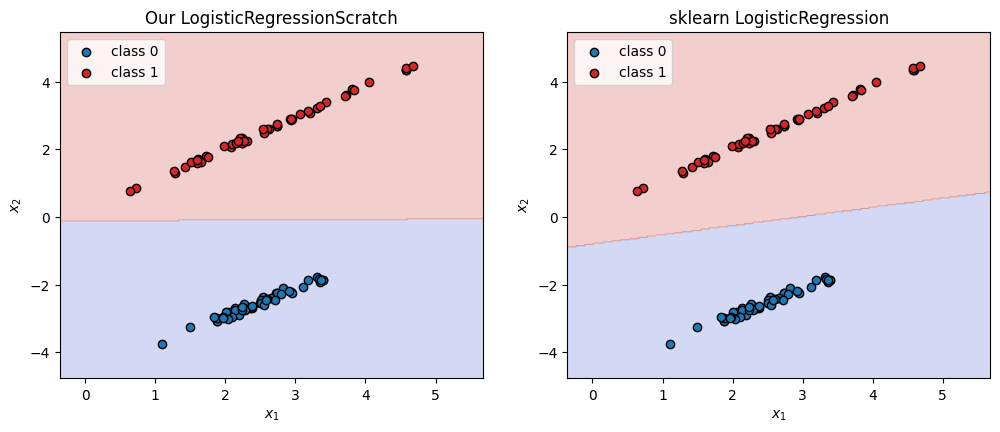

In [14]:
print("Our accuracy:    ", np.mean(pred == y))
print("sklearn accuracy:", np.mean(sk_pred == y))
print("Same predictions on", np.sum(pred == sk_pred), "out of", len(y), "points")
print("Max difference in P(y=1):", np.max(np.abs(proba - sk_proba[:, 1])).round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
plot_decision_boundary(model,    X, y, "Our LogisticRegressionScratch", ax=axes[0])
plot_decision_boundary(sk_model, X, y, "sklearn LogisticRegression",    ax=axes[1])
plt.show()

**Check yourself:** accuracy `1.0` for both, same predictions on `100` of 100 points, max probability difference `0.018`.

> Both models are perfect on the training set, yet the two lines are different. Give two reasons.

*Answer:* (1) the data is perfectly separable, so many lines give zero errors; which one you get depends on training details. (2) sklearn adds L2 **regularization** by default (`C=1.0`), which keeps $w$ small, and it uses a different optimizer (L-BFGS) with a convergence criterion, while we run a fixed number of plain gradient steps from $w = 0$.

Our class is intentionally simple and educational; sklearn provides a production-quality implementation.

## Part F. Small experiments

For each experiment, **write your prediction first**, then run the cell.

### Task 11. The learning rate

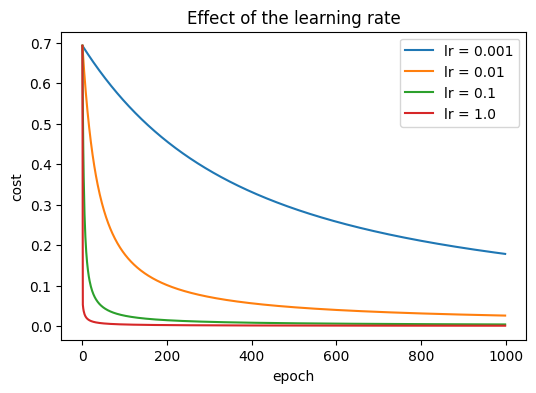

In [15]:
for lr in [0.001, 0.01, 0.1, 1.0]:
    m_lr = LogisticRegressionScratch(lr=lr, epochs=1000).fit(X, y)
    plt.plot(m_lr.loss_history, label=f"lr = {lr}")

plt.xlabel("epoch")
plt.ylabel("cost")
plt.title("Effect of the learning rate")
plt.legend()
plt.show()

*Answer:* the larger the learning rate, the faster the cost drops on this data. With `lr = 0.001` the cost is still high after 1000 epochs: the steps are too small.

### Task 12. Number of epochs

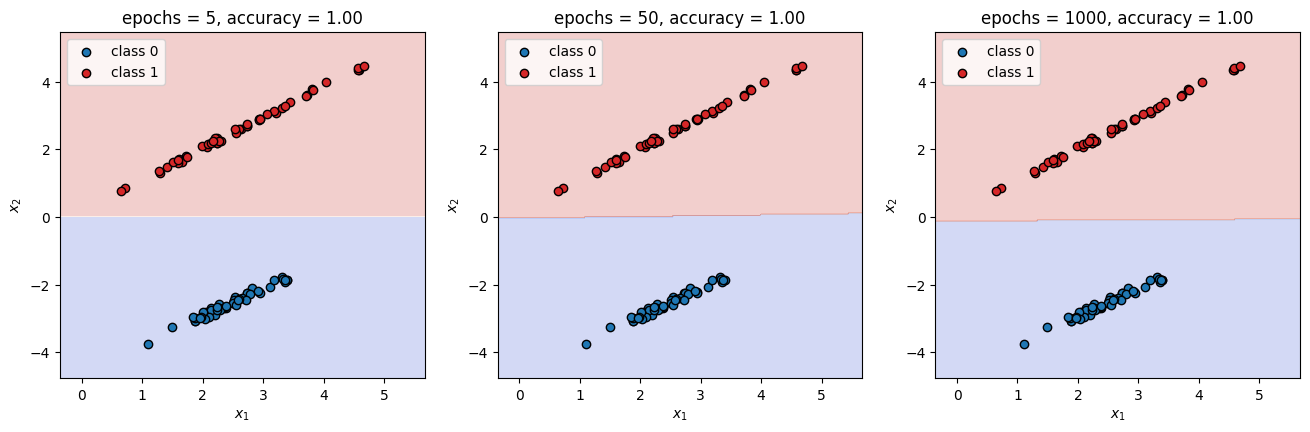

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, epochs in zip(axes, [5, 50, 1000]):
    m_ep = LogisticRegressionScratch(lr=0.1, epochs=epochs).fit(X, y)
    acc = np.mean(m_ep.predict(X) == y)
    plot_decision_boundary(m_ep, X, y, f"epochs = {epochs}, accuracy = {acc:.2f}", ax=ax)
plt.show()

*Answer:* on this easy dataset the boundary is already correct after a few epochs; more epochs mostly make the model more **confident** (larger $\|w\|$, lower loss) rather than changing the predictions.

### Task 13. Harder data

Training accuracy: 0.86


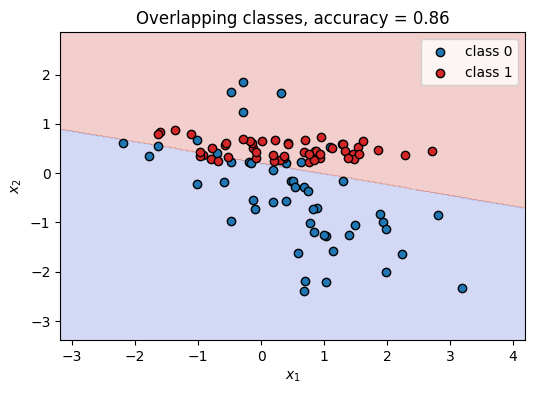

In [17]:
X_hard, y_hard = make_classification(
    n_samples=100, n_features=2, n_redundant=0, n_informative=2,
    n_clusters_per_class=1, class_sep=0.5, random_state=0
)

m_hard = LogisticRegressionScratch(lr=0.1, epochs=1000).fit(X_hard, y_hard)
acc = np.mean(m_hard.predict(X_hard) == y_hard)
print("Training accuracy:", acc)
plot_decision_boundary(m_hard, X_hard, y_hard, f"Overlapping classes, accuracy = {acc:.2f}")
plt.show()

**Check yourself:** training accuracy `0.86`.

*Answer:* no, the classes overlap, so some points are always on the wrong side and the accuracy drops below 1. The final loss stays clearly above 0.

## Summary

$$
z = w^T x + b \;\longrightarrow\; p = \sigma(z) \;\longrightarrow\; \text{BCE loss} \;\longrightarrow\; \text{gradient descent}
$$

Main idea:

> **Model the probability of class 1.**

```python
model = LogisticRegressionScratch(lr=0.1, epochs=1000)
model.fit(X, y)          # learns self.w and self.b
model.predict_proba(X)   # probabilities
model.predict(X)         # classes
```

Next lab: **SVM**. Same problem, same interface, a different idea of what makes a boundary "good".